# Restated vs Point-in-Time: Backtest Hygiene

Every positioning value exists in two revisions:

| Revision | `is_pit` | What it is | Use it for |
|---|---|---|---|
| **Restated** | `False` | Recomputed over the full history with today's inputs and today's model | Charts, monitoring, "where are we now" |
| **Point-in-time** | `True` | The value as it was **first published**, before later revisions | Backtests and signal research |

Restated history is cleaner and longer. It is also quietly informed by data that arrived after each date. This notebook
measures how much that matters:

1. The size of the gap across all 235 series
2. Whether it is just a normalisation artefact (it is not)
3. What it does to signals: crowding episodes in each revision
4. Publication lags: when each value could actually have been traded
5. A backtest-safe loader you can reuse

> Point-in-time values before September 2026 are **reconstructed** by replaying the pipeline as of each date. Values from
> September 2026 onward are captured live. The API serves both revisions via `revision="point_in_time"` (notebook 01).

In [1]:
import sys
import warnings
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

## 1. Load both revisions

In [2]:
catalog = qk.load_catalog("positioning")
restated = qk.pivot(pd.concat([qk.load("positioning", ds, revision="restated") for ds in catalog.dataset]))
pit = qk.pivot(pd.concat([qk.load("positioning", ds, revision="point_in_time") for ds in catalog.dataset]))

names = qk.names()
no_pit = sorted(set(restated.columns) - set(pit.columns))
print(f"restated: {restated.shape[1]} series · point-in-time: {pit.shape[1]} series")
print("no point-in-time history yet:", ", ".join(no_pit))

restated: 235 series · point-in-time: 222 series
no point-in-time history yet: KREQCOMB, KREQCOMB-COMS-BETA, KREQCOMB-DISC-BETA, KREQCOMB-ENER-BETA, KREQCOMB-FINA-BETA, KREQCOMB-HLTH-BETA, KREQCOMB-INDU-BETA, KREQCOMB-MATE-BETA, KREQCOMB-RLST-BETA, KREQCOMB-STAP-BETA, KREQCOMB-TECH-BETA, KREQCOMB-UTIL-BETA, TWEQCOMB


Restated history usually starts earlier, because reconstruction needs enough data to standardise. Per series:

In [3]:
starts = pd.DataFrame({"restated_from": restated.apply(lambda s: s.first_valid_index()), "pit_from": pit.apply(lambda s: s.first_valid_index())}).dropna()
starts["years_lost"] = (starts.pit_from - starts.restated_from).dt.days / 365.25
starts.years_lost.describe().round(1).to_frame("years between restated start and PIT start")

,years between restated start and PIT start
count,222.0
mean,2.0
std,2.3
min,-3.2
25%,0.0
50%,2.0
75%,3.0
max,9.7


## 2. How big is the gap?

On every date where both revisions exist, compare:

* **mean absolute difference** in σ
* **correlation** of levels
* **sign agreement**: do both say long, or both say short?
* **signal agreement**: do both classify the day the same way at ±1.5σ?

In [4]:
def compare(label: str) -> pd.Series:
    both = pd.concat({"r": restated[label], "p": pit[label]}, axis=1, sort=True).dropna()
    return pd.Series({
        "days": len(both),
        "mean_abs_diff": (both.r - both.p).abs().mean(),
        "corr": both.r.corr(both.p),
        "sign_agree": (np.sign(both.r) == np.sign(both.p)).mean(),
        "signal_agree": (both.r.map(qk.crowding_signal) == both.p.map(qk.crowding_signal)).mean(),
    })


gap = pd.DataFrame({label: compare(label) for label in pit.columns.intersection(restated.columns)}).T
gap = gap[gap.days >= 250]
gap.describe().loc[["mean", "25%", "50%", "75%", "min"]].round(3)

,days,mean_abs_diff,corr,sign_agree,signal_agree
mean,3039.602,0.329,0.911,0.894,0.905
25%,2594.000,0.197,0.891,0.844,0.862
50%,3203.000,0.304,0.941,0.906,0.910
75%,3723.000,0.464,0.981,0.950,0.952
min,768.000,0.000,0.398,0.687,0.649


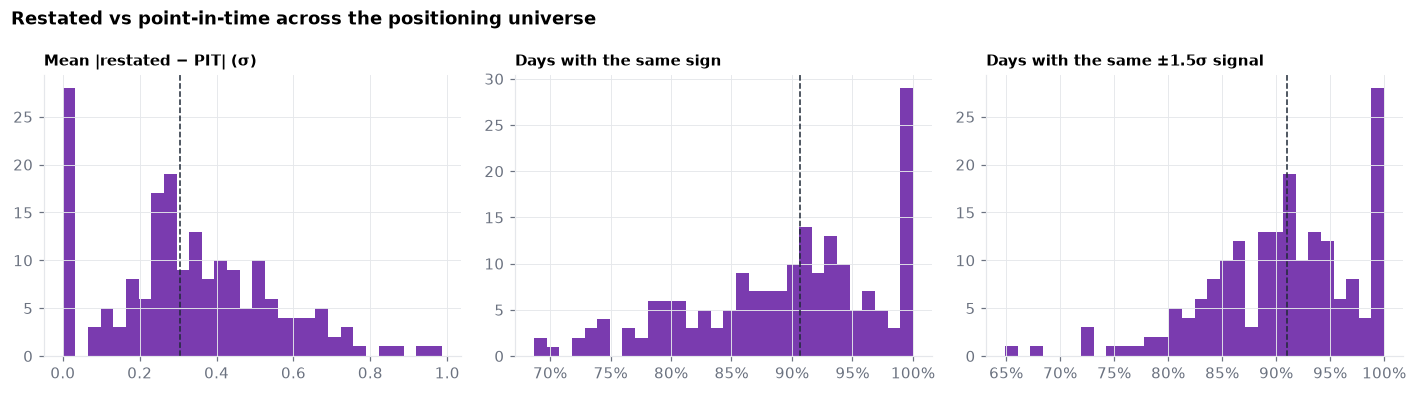

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, title in zip(axes, ["mean_abs_diff", "sign_agree", "signal_agree"],
                          ["Mean |restated − PIT| (σ)", "Days with the same sign", "Days with the same ±1.5σ signal"]):
    ax.hist(gap[col], bins=30, color=qk.VANDA["purple"], alpha=0.85)
    ax.axvline(gap[col].median(), color=qk.VANDA["ink"], ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    if col != "mean_abs_diff":
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Restated vs point-in-time across the positioning universe", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

On the median series the two revisions disagree on **direction about one day in ten**, and on the **crowding signal about
one day in ten**. For some series it is closer to one day in three:

In [6]:
worst = gap.sort_values("signal_agree").head(10).assign(name=lambda d: d.index.map(names))
worst[["name", "days", "mean_abs_diff", "corr", "sign_agree", "signal_agree"]].round(2)

,name,days,mean_abs_diff,corr,sign_agree,signal_agree
TWEQCOMB-UTIL,Taiwan Utilities,2813.0,0.99,0.60,0.87,0.65
USFICOMB-IG,US Investment Grade,4175.0,0.88,0.98,0.76,0.68
USFICOMB-MBS,US MBS,4089.0,0.93,1.00,0.79,0.72
TWEQCOMB-HLTH,Taiwan Health care,2813.0,0.74,0.70,0.96,0.72
USFICOMB-2YR,UST 2Y,3203.0,0.85,0.41,0.70,0.72
TWEQCOMB-INDU,Taiwan Industrials,2813.0,0.68,0.72,0.84,0.75
TWEQCOMB-TECH,Taiwan Tech,2813.0,0.65,0.91,0.93,0.76
USEQCOMB-MTUM,US Momentum,3130.0,0.73,0.65,0.78,0.77
KREQCOMB-TECH,Korea Tech,2023.0,0.62,0.85,0.92,0.78
PHEQCOMB-MATE,Philippines Materials,771.0,0.71,0.88,0.85,0.79


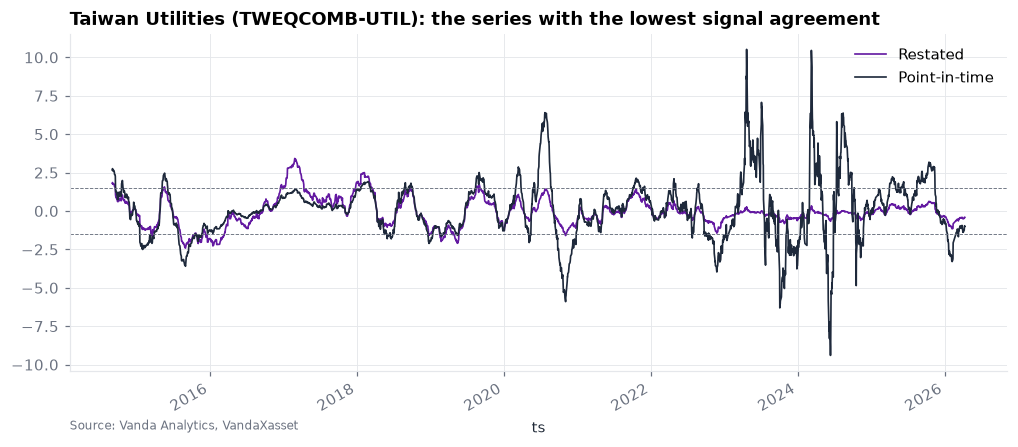

In [7]:
example = gap.sort_values("signal_agree").index[0]
both = pd.concat({"Restated": restated[example], "Point-in-time": pit[example]}, axis=1, sort=True).dropna()

ax = both.plot(lw=1.1, title=f"{names.get(example, example)} ({example}): the series with the lowest signal agreement")
for level in (-qk.CROWDING_THRESHOLD, qk.CROWDING_THRESHOLD):
    ax.axhline(level, color=qk.VANDA["sub"], lw=0.6, ls="--")
qk.source_note(ax)
plt.show()

## 3. Is it just the normalisation?

Restated z-scores are standardised against the **full sample** mean and standard deviation, which includes the future. If
that were the whole story, re-standardising restated values on an **expanding** window (only data up to each date) would
reproduce the point-in-time series.

In [8]:
rows = []
for label in gap.index:
    expanding = qk.expanding_zscore(restated[label].dropna(), min_periods=252)
    both = pd.concat({"r": restated[label], "e": expanding, "p": pit[label]}, axis=1, sort=True).dropna()
    rows.append({
        "label": label,
        "corr: restated": both.r.corr(both.p),
        "corr: re-standardised": both.e.corr(both.p),
        "|gap|: restated": (both.r - both.p).abs().mean(),
        "|gap|: re-standardised": (both.e - both.p).abs().mean(),
    })

restandard = pd.DataFrame(rows).set_index("label")
closed = 1 - restandard["|gap|: re-standardised"].median() / restandard["|gap|: restated"].median()
print(restandard.median().round(3).rename("median across series").to_frame())
print(f"\nShare of the median absolute gap closed by re-standardising: {closed:.0%}")

                        median across series
corr: restated                         0.942
corr: re-standardised                  0.961
|gap|: restated                        0.307
|gap|: re-standardised                 0.276

Share of the median absolute gap closed by re-standardising: 10%


It helps a little: correlation rises, but the typical absolute gap barely moves. Most of the gap comes from **revisions to the underlying inputs** (late or corrected source data,
reclassified flows) and from model improvements. You cannot strip it out after the fact, so the only clean
backtest input is the point-in-time series.

## 4. What it does to signals

A backtest only ever sees **signals**: the days a series crosses ±1.5σ. Count the crowding episodes each revision would
have fired over the same dates, and how many of them the other revision also fired within a week.

In [9]:
def episodes(s: pd.Series, cooldown_days: int = 60) -> tuple:
    """First crossings of ±1.5σ, one per side per 60 days (as in notebook 05)."""
    dates, sides = [], []
    for side in (1, -1):
        beyond = (s * side) > qk.CROWDING_THRESHOLD
        last = None
        for d in s.index[beyond & ~beyond.shift(1, fill_value=False)]:
            if last is None or (d - last).days >= cooldown_days:
                dates.append(d)
                sides.append(side)
                last = d
    return pd.DatetimeIndex(dates), pd.Series(sides)


rows = []
for label in gap.index:
    both = pd.concat({"r": restated[label], "p": pit[label]}, axis=1, sort=True).dropna()
    r_dates, r_side = episodes(both.r)
    p_dates, p_side = episodes(both.p)
    window = pd.Timedelta(days=7)
    matched = sum(any(abs((p_dates[p_side.values == sd] - d)) <= window) for d, sd in zip(r_dates, r_side.values))
    rows.append({"label": label, "restated episodes": len(r_dates), "point-in-time episodes": len(p_dates), "restated also in PIT": matched})

signals = pd.DataFrame(rows).set_index("label")
totals = signals.sum()
print(f"Restated history fires {totals['restated episodes']:,} crowding episodes; point-in-time fires {totals['point-in-time episodes']:,}.")
print(f"Only {totals['restated also in PIT'] / totals['restated episodes']:.0%} of restated episodes also appear in the point-in-time series within a week.")

Restated history fires 2,689 crowding episodes; point-in-time fires 3,024.
Only 47% of restated episodes also appear in the point-in-time series within a week.


In [10]:
signals["share confirmed"] = signals["restated also in PIT"] / signals["restated episodes"]
by_asset = signals.join(qk.series_reference().set_index("series_label")["asset_type"]).groupby("asset_type")[
    ["restated episodes", "point-in-time episodes", "restated also in PIT"]].sum()
by_asset["share confirmed"] = (by_asset["restated also in PIT"] / by_asset["restated episodes"]).round(2)
by_asset

,restated episodes,point-in-time episodes,restated also in PIT,share confirmed
asset_type,,,,
COM,357,263,91,0.25
EQ,1341,1650,496,0.37
FI,454,574,149,0.33
FX,537,537,537,1.00


FX positioning is not revised in this sample, so its two revisions agree exactly. Elsewhere, any strategy, event study or screen built on restated history is trading many signals that, in real time, **fired
at a different moment or not at all**, and is missing some that did fire. The rule cannot be fixed after the fact: run research on point-in-time inputs.

## 5. Publication lags

A value stamped `ts = Monday` is not necessarily *available* on Monday. The series reference records each series'
publication `lag` (days after the observation date) and its expected `update_time`. Most positioning publishes the
next day; flow fed by weekly or monthly sources can lag up to three weeks.

In [11]:
ref = qk.series_reference()
ref.pivot_table(index="family", columns="lag", values="series_label", aggfunc="count", fill_value=0)

lag,1,2,5,7,14,21
family,,,,,,
flow,584,108,0,288,17,6
positioning,205,2,1,12,13,2


In [12]:
ref[(ref.family == "positioning") & (ref.lag > 1)][["series_label", "name", "frequency", "lag", "update_time"]].sort_values("lag", ascending=False).head(12)

,series_label,name,frequency,lag,update_time
1195,PHFICOMB,Philippines Bonds,monthly,21,05:00:00
1015,BRFICOMB,Brazil Bonds,monthly,21,00:00:00
1134,INEQCOMB-COMS,India Com. Serv.,bi-weekly,14,15:00:00
1135,INEQCOMB-DISC,India Cons. Disc,bi-weekly,14,15:00:00
1183,MXFICOMB,Mexico Bonds,daily,14,07:00:00
1144,INEQCOMB-UTIL,India Utilities,bi-weekly,14,15:00:00
1143,INEQCOMB-TECH,India Tech,bi-weekly,14,15:00:00
1142,INEQCOMB-STAP,India Cons. Staples,bi-weekly,14,15:00:00
1141,INEQCOMB-RLST,India Real Estate,bi-weekly,14,15:00:00
1140,INEQCOMB-MATE,India Materials,bi-weekly,14,15:00:00


## 6. A backtest-safe loader

Putting it together:

1. Use **point-in-time** where it exists, and say so loudly when it does not.
2. Move each value to the business day it became available (`ts + lag`). If two observations land on the same day (a
   weekend print, say), keep the later one.
3. Keep a `revision` column so every downstream result can be audited.

In [13]:
def backtest_series(label: str) -> pd.DataFrame:
    meta = qk.describe(label)
    dataset = meta["dataset"]
    lag_days = int(meta.get("lag", 1))

    df = qk.load("positioning", dataset, series=label, revision="point_in_time")
    revision = "point_in_time"
    if df.empty:
        warnings.warn(f"{label}: no point-in-time history, falling back to restated. Treat results as optimistic.")
        df = qk.load("positioning", dataset, series=label, revision="restated")
        revision = "restated"

    out = df[["ts", "value"]].rename(columns={"ts": "observed"})
    out["available"] = out["observed"] + pd.offsets.BDay(lag_days)
    out["revision"] = revision
    return out.groupby("available").last()


backtest_series("USFICOMB-10YR").tail()

,observed,value,revision
available,,,
2026-04-07,2026-04-06,0.994482,point_in_time
2026-04-08,2026-04-07,0.995493,point_in_time
2026-04-09,2026-04-08,1.067229,point_in_time
2026-04-10,2026-04-09,1.066453,point_in_time
2026-04-13,2026-04-10,1.062588,point_in_time


In [14]:
backtest_series("KREQCOMB").tail(3)

,observed,value,revision
available,,,
2026-04-09,2026-04-08,1.688728,restated
2026-04-10,2026-04-09,1.777474,restated
2026-04-13,2026-04-10,1.840282,restated


### Checklist before trusting a VandaXasset backtest

- [ ] Inputs are `revision="point_in_time"` (or the gap is explicitly measured and disclosed)
- [ ] Signals are shifted to their **availability** date, not their observation date
- [ ] Weekly or monthly series are forward-filled only until the next release, never beyond
- [ ] One dataset version throughout; a version switch mid-backtest is a structural break
- [ ] Results hold with an extra day of execution delay

---
**Next:** `05 - Positioning Extremes - How Long Crowding Lasts`, a point-in-time study of crowding episodes.